# Modeling Human Activity States Using Hidden Markov Models

**Student:** Mukunzi Ndahiro James  
**Course:** Machine Learning Techniques II  
**Assignment:** Formative 2 – Hidden Markov Models (individual)

In this notebook I build a Hidden Markov Model from scratch in NumPy to recognise four activities (**standing, walking, jumping and still**) from the accelerometer and gyroscope of my own phone.

| Section | Content |
|---|---|
| 1 | Data collection and quality checks |
| 2 | Preprocessing and windowing |
| 3 | Feature extraction and normalisation |
| 4 | HMM definition, Baum–Welch training and Viterbi decoding |
| 5 | Evaluation on unseen data |
| 6 | Conclusion |

I import the standard scientific Python stack and my own modules from `src/`: `preprocessing`, `features`, `hmm`, `train` and `evaluation`.

In [1]:
import sys
import inspect
import itertools
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from scipy.stats import norm

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from src import preprocessing as pp
from src import features as ft
from src import evaluation as ev
from src.hmm import GaussianHMM, logsumexp
from src.train import CLIPS_PER_SESSION, HMM_CONFIG, MODEL_PATH, chain_clips, initialise, to_sequences, train_hmm

PLOTS = ROOT / "plots"
PLOTS.mkdir(exist_ok=True)

ACTIVITIES = pp.ACTIVITIES
COLORS = {"standing": "#4C72B0", "walking": "#55A868", "jumping": "#C44E52", "still": "#8172B2"}
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

## 1. Data collection

I recorded all data myself with **Sensor Logger 1.68 on my iPhone 13** at 100 Hz (one sample every 10 ms), logging the accelerometer, gyroscope and gravity sensors.

- **Training:** 20 clips per activity (80 in total), each 5–10 s long. For standing I held the phone steady at waist level, for still I placed it flat on a table.
- **Testing:** two separate continuous sessions of about 40 s in which I performed all four activities back to back.

`build_dataset.py` merged the sensor files of each recording into one labelled CSV (`data/raw/<activity>_<NN>.csv` and `data/test/mixed_<NN>.csv`). I trimmed clips longer than 10 s equally from both ends. Below I load every CSV and compute the number of samples and the duration from its timestamps.

In [2]:
rows = []
for path in sorted((ROOT / "data" / "raw").glob("*.csv")) + sorted((ROOT / "data" / "test").glob("*.csv")):
    df = pd.read_csv(path)
    rows.append({"file": path.name, "set": "test" if path.name.startswith("mixed") else "train",
                 "activity": " → ".join(df["activity"].loc[df["activity"].ne(df["activity"].shift())]),
                 "samples": len(df), "duration_s": (df["time"].iloc[-1] - df["time"].iloc[0]) / 1e9,
                 "fs": df["fs"].iloc[0], "device": df["device"].iloc[0]})
files = pd.DataFrame(rows)

(files[files["set"] == "train"].groupby("activity")
 .agg(clips=("file", "count"), samples=("samples", "sum"), total_s=("duration_s", "sum"),
      min_s=("duration_s", "min"), max_s=("duration_s", "max"))
 .reindex(ACTIVITIES))

,clips,samples,total_s,min_s,max_s
activity,,,,,
standing,20,19254,193.725,8.662,10.000
walking,20,19849,199.715,9.981,9.992
jumping,20,18565,186.784,8.722,9.981
still,20,19848,199.698,9.980,9.992


In [3]:
files[files["set"] == "test"].drop(columns="set")

,file,activity,samples,duration_s,fs,device
80,mixed_01.csv,standing → walking → jumping → still,4039,40.669,100,iPhone 13
81,mixed_02.csv,walking → still → jumping → standing,4034,40.619,100,iPhone 13


In [4]:
pd.read_csv(ROOT / "data" / "raw" / "walking_01.csv").head()

,time,seconds_elapsed,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,grav_x,grav_y,grav_z,fs,activity,participant,device
0,1793122710798342700,0.00,0.067,-2.647,1.261,-0.140,-0.102,0.122,0.260,-2.406,-9.503,100,walking,james,iPhone 13
1,1793122710808414700,0.01,0.008,-2.799,1.185,-0.225,-0.079,0.112,0.248,-2.389,-9.508,100,walking,james,iPhone 13
2,1793122710818485800,0.02,-0.151,-2.937,0.899,-0.318,-0.028,0.082,0.241,-2.363,-9.515,100,walking,james,iPhone 13
3,1793122710828557800,0.03,-0.288,-3.001,0.578,-0.414,0.026,0.050,0.239,-2.328,-9.523,100,walking,james,iPhone 13
4,1793122710838628900,0.04,-0.356,-3.013,0.223,-0.484,0.046,0.023,0.242,-2.285,-9.534,100,walking,james,iPhone 13


### Sampling rate check

I measured the real sampling rate from the timestamps of all 82 files to confirm the nominal 100 Hz and to look for gaps. As this is an individual assignment there is one participant and one phone.

In [5]:
rows = []
for path in sorted((ROOT / "data" / "raw").glob("*.csv")) + sorted((ROOT / "data" / "test").glob("*.csv")):
    df = pd.read_csv(path, usecols=["time", "participant", "device", "fs"])
    dt = np.diff(df["time"].to_numpy()) / 1e6
    rows.append({"file": path.name, "participant": df["participant"].iloc[0],
                 "device": df["device"].iloc[0], "nominal_fs": df["fs"].iloc[0],
                 "median_dt_ms": np.median(dt), "effective_fs": 1000 / np.median(dt),
                 "max_gap_ms": dt.max()})
rates = pd.DataFrame(rows)

rates.groupby(["participant", "device"]).agg(
    files=("file", "count"), nominal_fs=("nominal_fs", "first"),
    effective_fs=("effective_fs", "mean"), median_dt_ms=("median_dt_ms", "mean"),
    worst_gap_ms=("max_gap_ms", "max"))

,,files,nominal_fs,effective_fs,median_dt_ms,worst_gap_ms
participant,device,,,,,
james,iPhone 13,82,100,99.288,10.072,11.331


### Raw signals per activity

I plot one clip per activity. The accelerometer values are user acceleration (gravity removed), so still and standing stay close to zero while walking and jumping show regular peaks.

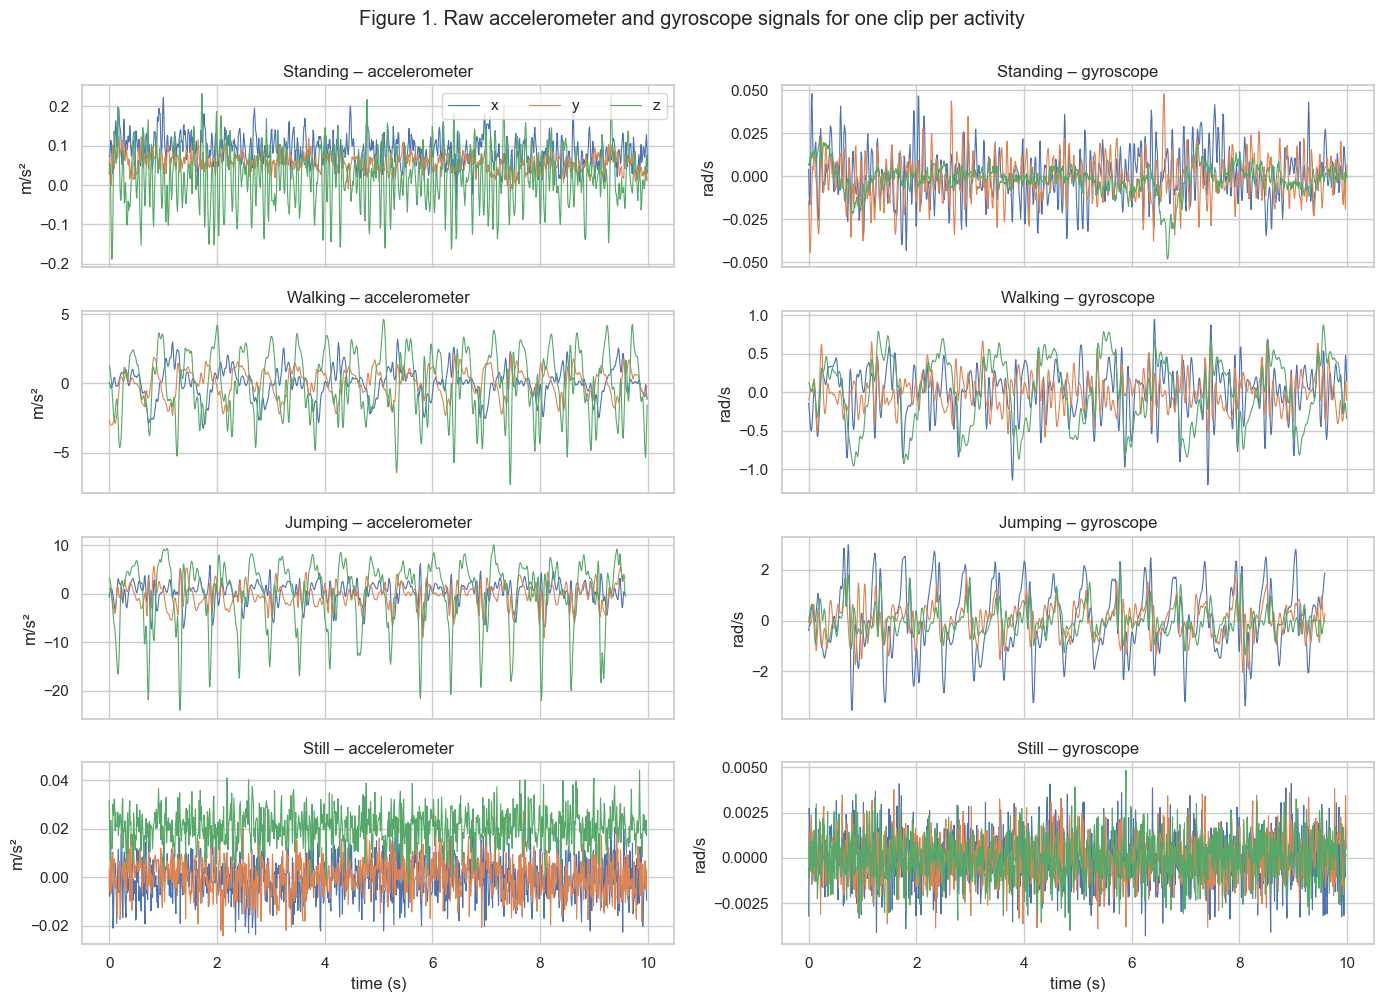

In [6]:
fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(14, 10), sharex=True)
for row, activity in enumerate(ACTIVITIES):
    df = pd.read_csv(ROOT / "data" / "raw" / f"{activity}_01.csv")
    for col, (sensor, unit) in enumerate([("acc", "m/s²"), ("gyr", "rad/s")]):
        ax = axes[row, col]
        for axis in "xyz":
            ax.plot(df["seconds_elapsed"], df[f"{sensor}_{axis}"], lw=0.8, label=axis)
        ax.set_title(f"{activity.capitalize()} – {'accelerometer' if sensor == 'acc' else 'gyroscope'}")
        ax.set_ylabel(unit)
axes[0, 0].legend(loc="upper right", ncol=3)
axes[-1, 0].set_xlabel("time (s)")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle("Figure 1. Raw accelerometer and gyroscope signals for one clip per activity", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "raw_signals.png", dpi=150, bbox_inches="tight")
plt.show()

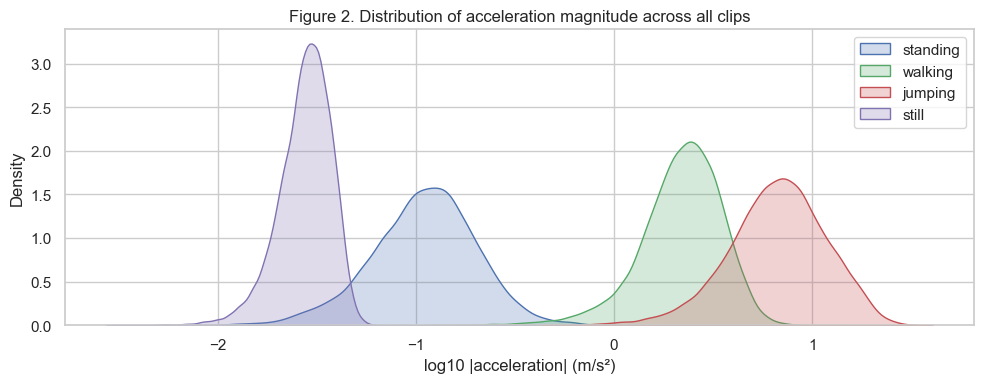

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for activity in ACTIVITIES:
    mags = []
    for path in sorted((ROOT / "data" / "raw").glob(f"{activity}_*.csv")):
        df = pd.read_csv(path)
        mags.append(np.sqrt(df.acc_x**2 + df.acc_y**2 + df.acc_z**2))
    sns.kdeplot(np.log10(np.concatenate(mags) + 1e-3), ax=ax, label=activity,
                color=COLORS[activity], fill=True, alpha=0.25)
ax.set_xlabel("log10 |acceleration| (m/s²)")
ax.set_title("Figure 2. Distribution of acceleration magnitude across all clips")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "acc_magnitude_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Unseen test sessions

I recorded the two test sessions after all training clips, each in a different activity order. I labelled the activity boundaries from my recording protocol (about 10 s per activity) and refined them to the nearest 0.25 s where the signal clearly changes.

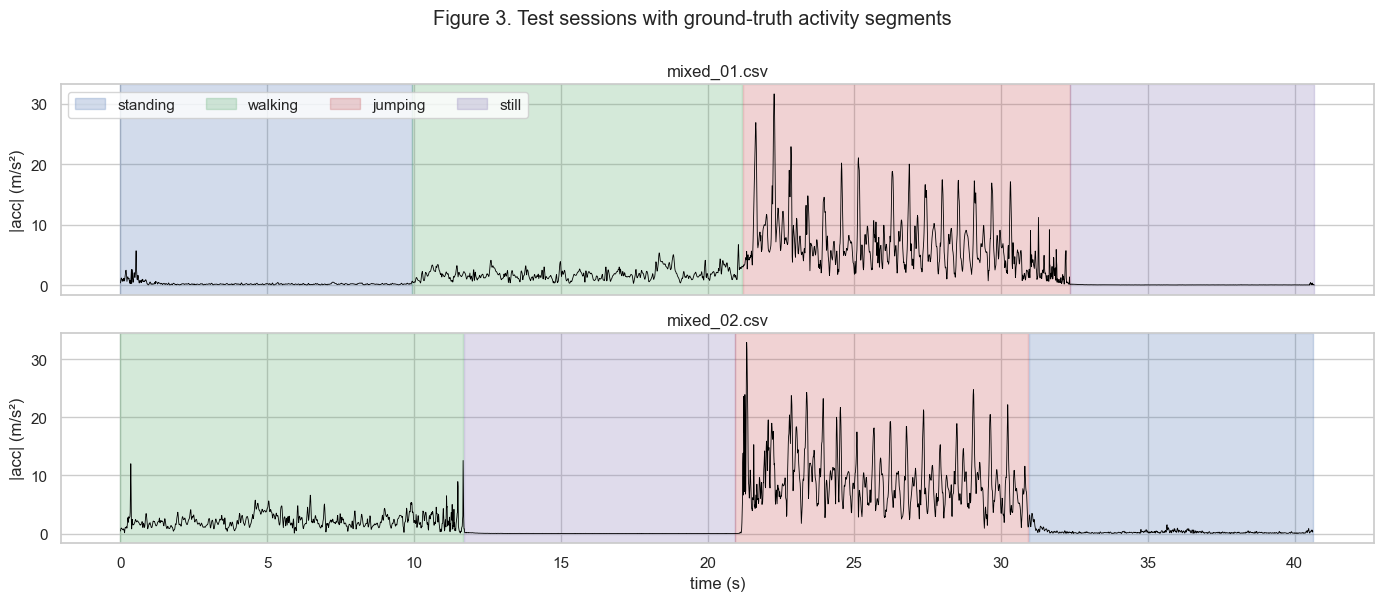

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, name in zip(axes, ["mixed_01.csv", "mixed_02.csv"]):
    df = pd.read_csv(ROOT / "data" / "test" / name)
    mag = np.sqrt(df.acc_x**2 + df.acc_y**2 + df.acc_z**2)
    ax.plot(df["seconds_elapsed"], mag, color="black", lw=0.6)
    change = df["activity"].ne(df["activity"].shift()).cumsum()
    for _, seg in df.groupby(change):
        ax.axvspan(seg["seconds_elapsed"].iloc[0], seg["seconds_elapsed"].iloc[-1],
                   color=COLORS[seg["activity"].iloc[0]], alpha=0.25, label=seg["activity"].iloc[0])
    ax.set_title(name)
    ax.set_ylabel("|acc| (m/s²)")
handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[0].legend(unique.values(), unique.keys(), loc="upper left", ncol=4)
axes[-1].set_xlabel("time (s)")
fig.suptitle("Figure 3. Test sessions with ground-truth activity segments", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "test_sessions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Preprocessing and windowing

| Step | Setting | Why I chose it |
|---|---|---|
| Resampling | uniform 100 Hz grid (linear interpolation) | removes timestamp jitter; a phone with another rate (e.g. 50 Hz) lands on the same grid, so every window has the same length and the same FFT bins (tested in Section 5) |
| Low-pass filter | 4th-order Butterworth, 20 Hz, zero-phase | human movement is below 20 Hz; this removes sensor noise without shifting the signal in time |
| Edge trim | 0.5 s at each end of training clips | removes the tap on the screen when I start and stop recording |
| Window | 2.0 s = 200 samples at 100 Hz | holds at least two walking or jumping cycles (about 2 Hz) and gives an FFT resolution of fs / N = 100 / 200 = 0.5 Hz |
| Overlap | 50 % (step of 100 samples) | one observation per second for the HMM |

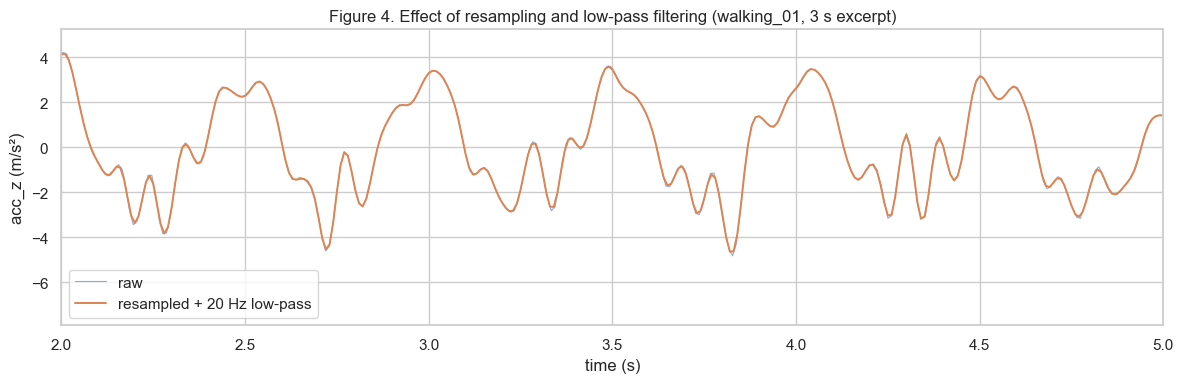

In [9]:
path = ROOT / "data" / "raw" / "walking_01.csv"
raw = pp.load_recording(path)
filtered = pp.lowpass_filter(pp.resample_uniform(raw))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw["seconds_elapsed"], raw["acc_z"], lw=0.8, alpha=0.6, label="raw")
ax.plot(filtered["seconds_elapsed"], filtered["acc_z"], lw=1.4, label="resampled + 20 Hz low-pass")
ax.set_xlim(2, 5)
ax.set_xlabel("time (s)")
ax.set_ylabel("acc_z (m/s²)")
ax.set_title("Figure 4. Effect of resampling and low-pass filtering (walking_01, 3 s excerpt)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "filtering.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
train_seqs = pp.load_training_windows()
test_seqs = pp.load_test_windows()

print(f"Window: {pp.WINDOW_S} s = {pp.WINDOW_SIZE} samples, step = {pp.STEP_SIZE} samples "
      f"({int(pp.OVERLAP * 100)}% overlap), FFT resolution = {pp.TARGET_FS / pp.WINDOW_SIZE} Hz")

window_counts = pd.DataFrame({
    "training": pd.Series(np.concatenate([s["labels"] for s in train_seqs])).value_counts(),
    **{s["file"]: pd.Series(s["labels"]).value_counts() for s in test_seqs},
}).reindex(ACTIVITIES).fillna(0).astype(int)
window_counts.loc["total"] = window_counts.sum()
window_counts

Window: 2.0 s = 200 samples, step = 100 samples (50% overlap), FFT resolution = 0.5 Hz


,training,mixed_01.csv,mixed_02.csv
standing,145,9,9
walking,149,12,11
jumping,135,11,10
still,148,7,9
total,577,39,39


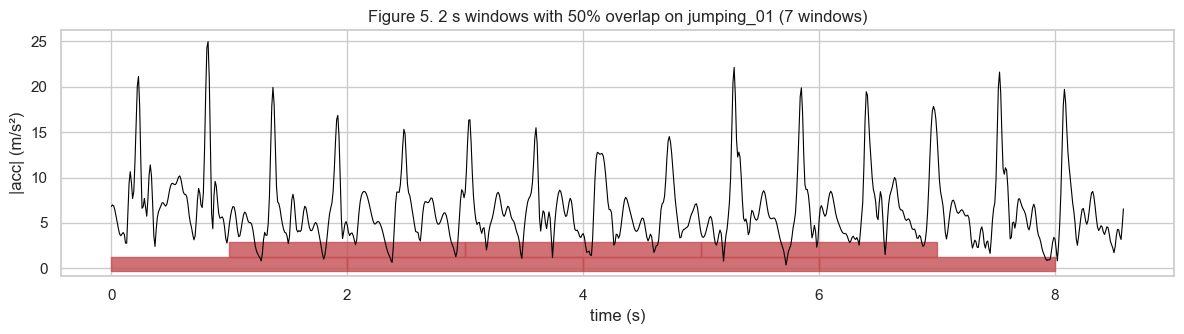

In [11]:
seq = next(s for s in train_seqs if s["file"] == "jumping_01.csv")
sig = seq["signal"]
mag = np.sqrt(sig.acc_x**2 + sig.acc_y**2 + sig.acc_z**2)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(sig["seconds_elapsed"], mag, color="black", lw=0.8)
for i, start in enumerate(seq["start_s"]):
    ax.axvspan(start, start + pp.WINDOW_S, ymin=0.02 + 0.06 * (i % 2), ymax=0.08 + 0.06 * (i % 2),
               color=COLORS["jumping"], alpha=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("|acc| (m/s²)")
ax.set_title(f"Figure 5. 2 s windows with 50% overlap on jumping_01 ({len(seq['start_s'])} windows)")
fig.tight_layout()
fig.savefig(PLOTS / "windowing.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Feature extraction

I describe each 2 s window with **14 features: 9 time-domain and 5 frequency-domain**. For the frequency features I project the acceleration onto the gravity direction to get the **vertical acceleration**, apply a Hann window and take the FFT. This measures the step and jump rhythm no matter how I hold the phone.

In [12]:
pd.DataFrame([{"feature": name, "domain": domain, "why it separates the activities": why}
              for name, (domain, why) in ft.FEATURE_DESCRIPTIONS.items()])

,feature,domain,why it separates the activities
0,acc_mag_mean,time,average intensity of body acceleration
1,acc_mag_std,time,"variability of acceleration; near zero when still, very high when jumping"
2,acc_rms,time,energy of the acceleration signal in the time domain
3,acc_sma,time,"signal magnitude area, total movement across the three axes"
4,acc_ptp,time,peak-to-peak range; captures landing impacts of jumps
5,gyr_mag_std,time,variability of rotation; separates a hand-held phone (standing) from a phone on a table (still)
6,gyr_sma,time,total rotation across the three axes; walking and jumping swing the phone
7,acc_corr_yz,time,"correlation between vertical and forward axes; coordinated during gait, random when idle"
8,tilt_deg,time,"phone tilt from horizontal computed from gravity; flat on a table when still, upright when held"
9,vert_dom_freq,frequency,"dominant FFT frequency of vertical acceleration; step rate for walking, jump rate for jumping"


In [13]:
train_feat, test_feat, train_raw, test_raw, normalizer = ft.build_feature_sets(save=True)
print(f"Training windows: {len(train_feat)} | test windows: {len(test_feat)} | features: {len(ft.FEATURE_NAMES)}")
train_raw.groupby("activity")[ft.FEATURE_NAMES].mean().reindex(ACTIVITIES).T

Training windows: 577 | test windows: 78 | features: 14


activity,standing,walking,jumping,still
acc_mag_mean,0.120,2.379,7.873,2.613e-02
acc_mag_std,0.058,0.975,3.670,4.536e-03
acc_rms,0.133,2.573,8.708,2.653e-02
acc_sma,0.177,3.418,11.202,3.413e-02
acc_ptp,0.297,5.131,18.662,2.399e-02
gyr_mag_std,0.016,0.226,1.099,5.341e-04
gyr_sma,0.049,0.765,3.009,1.911e-03
acc_corr_yz,-0.254,0.345,0.130,-1.894e-02
tilt_deg,11.876,19.274,18.181,1.060e+00
vert_dom_freq,5.834,1.997,1.974,7.389e+00


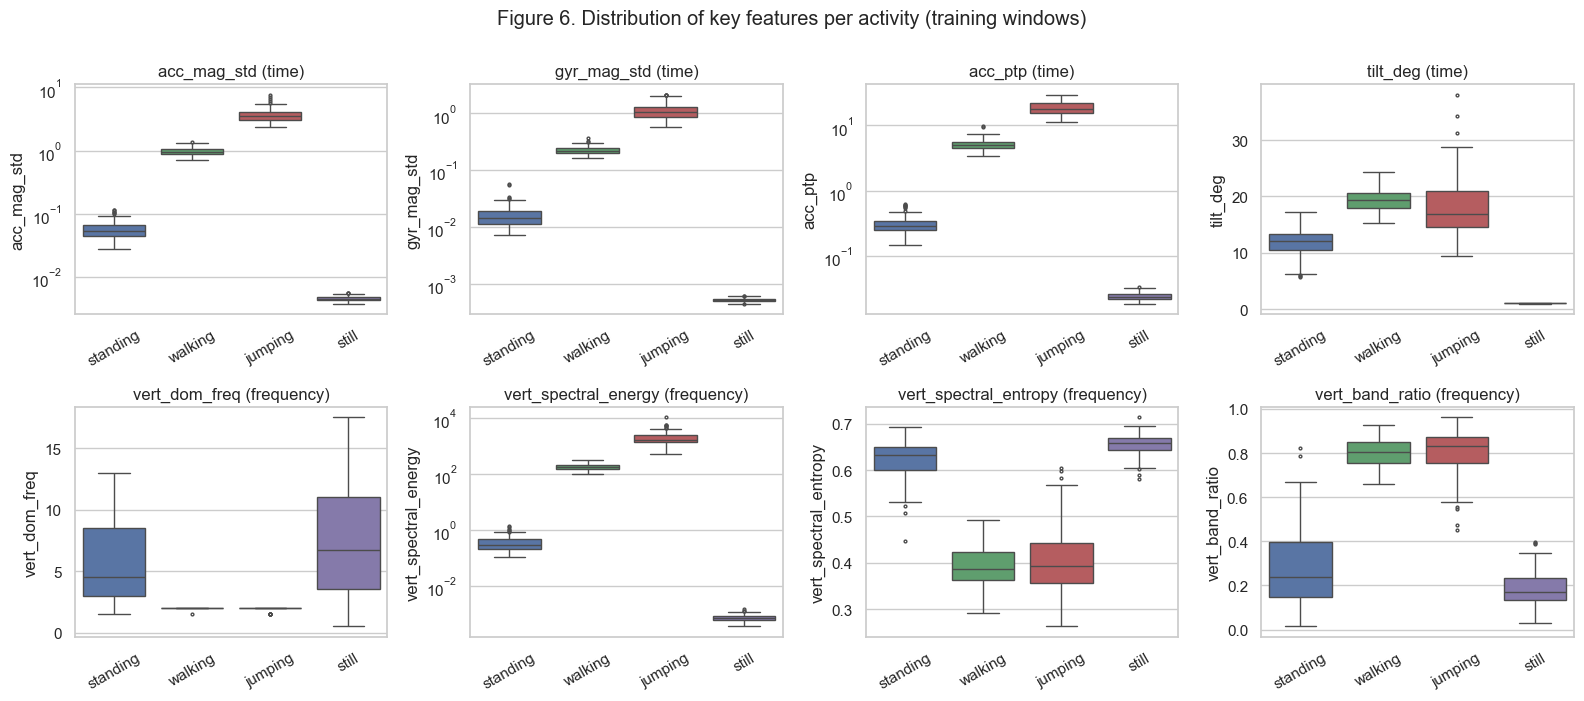

In [14]:
key_features = ["acc_mag_std", "gyr_mag_std", "acc_ptp", "tilt_deg",
                "vert_dom_freq", "vert_spectral_energy", "vert_spectral_entropy", "vert_band_ratio"]
log_scale = set(ft.LOG_FEATURES)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feat in zip(axes.flat, key_features):
    sns.boxplot(data=train_raw, x="activity", y=feat, order=ACTIVITIES, hue="activity",
                palette=COLORS, legend=False, ax=ax, fliersize=2)
    if feat in log_scale:
        ax.set_yscale("log")
    ax.set_title(f"{feat} ({ft.FEATURE_DESCRIPTIONS[feat][0]})")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Figure 6. Distribution of key features per activity (training windows)", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

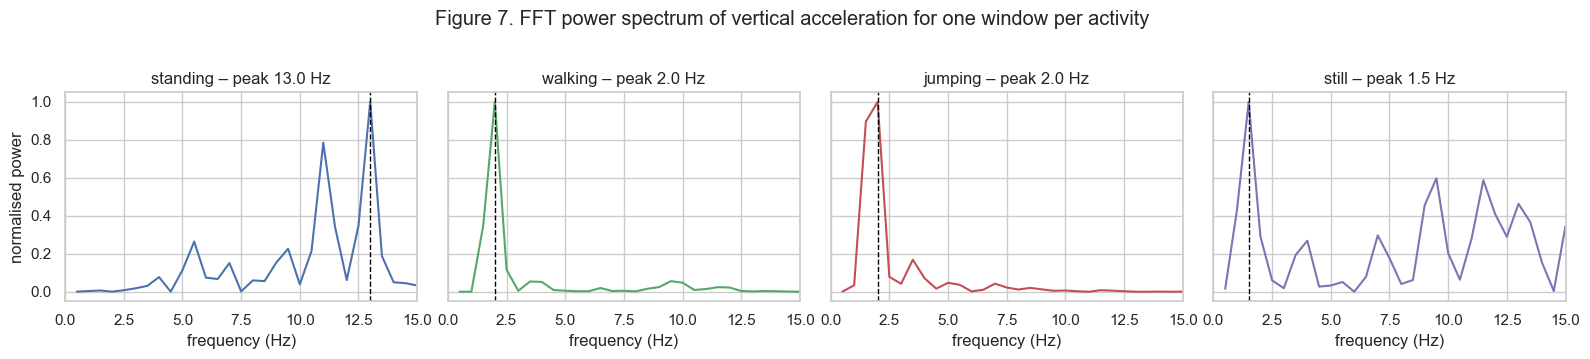

In [15]:
first_clips = {s["file"]: s for s in train_seqs if s["file"].endswith("_01.csv")}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, activity in zip(axes, ACTIVITIES):
    w = first_clips[f"{activity}_01.csv"]["windows"][3]
    g = w[:, 6:9].mean(axis=0)
    vertical = w[:, 0:3] @ (g / np.linalg.norm(g))
    freqs, power = ft.spectrum(vertical, pp.TARGET_FS)
    peak = ft.dominant_frequency(freqs, power)
    ax.plot(freqs, power / power.max(), color=COLORS[activity])
    ax.axvline(peak, ls="--", color="black", lw=1)
    ax.set_xlim(0, 15)
    ax.set_title(f"{activity} – peak {peak:.1f} Hz")
    ax.set_xlabel("frequency (Hz)")
axes[0].set_ylabel("normalised power")
fig.suptitle("Figure 7. FFT power spectrum of vertical acceleration for one window per activity", y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / "fft_spectra.png", dpi=150, bbox_inches="tight")
plt.show()

### Normalisation

My features have very different scales: spectral energy goes from 0.001 to over 2000, entropy is between 0 and 1, and tilt is in degrees. Because my HMM uses Gaussian emissions, I:

1. apply **log10** to the eight magnitude and energy features, which span several orders of magnitude and are right-skewed, so they become closer to Gaussian;
2. apply **Z-score normalisation** `z = (x − μ) / σ`, with μ and σ computed on the **training windows only** and reused for the test windows, so nothing from the unseen data leaks into training.

I chose Z-score over min-max scaling because hard jump landings would squeeze all other min-max values into a narrow range, while Z-score gives every feature unit variance so no single feature dominates the Gaussian likelihood.

In [16]:
pd.DataFrame({"train mean": train_feat[ft.FEATURE_NAMES].mean(),
              "train std": train_feat[ft.FEATURE_NAMES].std(ddof=0),
              "test mean": test_feat[ft.FEATURE_NAMES].mean(),
              "test std": test_feat[ft.FEATURE_NAMES].std(ddof=0)}).round(3)

,train mean,train std,test mean,test std
acc_mag_mean,-0.0,1.0,0.210,0.903
acc_mag_std,0.0,1.0,0.304,0.915
acc_rms,0.0,1.0,0.238,0.910
acc_sma,0.0,1.0,0.222,0.890
acc_ptp,-0.0,1.0,0.303,0.907
gyr_mag_std,0.0,1.0,0.365,0.942
gyr_sma,-0.0,1.0,0.276,0.914
acc_corr_yz,0.0,1.0,-0.245,1.171
tilt_deg,0.0,1.0,0.138,1.036
vert_dom_freq,0.0,1.0,-0.029,1.123


### Feature redundancy

My HMM uses a diagonal covariance, which treats features as independent **within** an activity. I check the average within-activity correlation to see which features carry the same information.

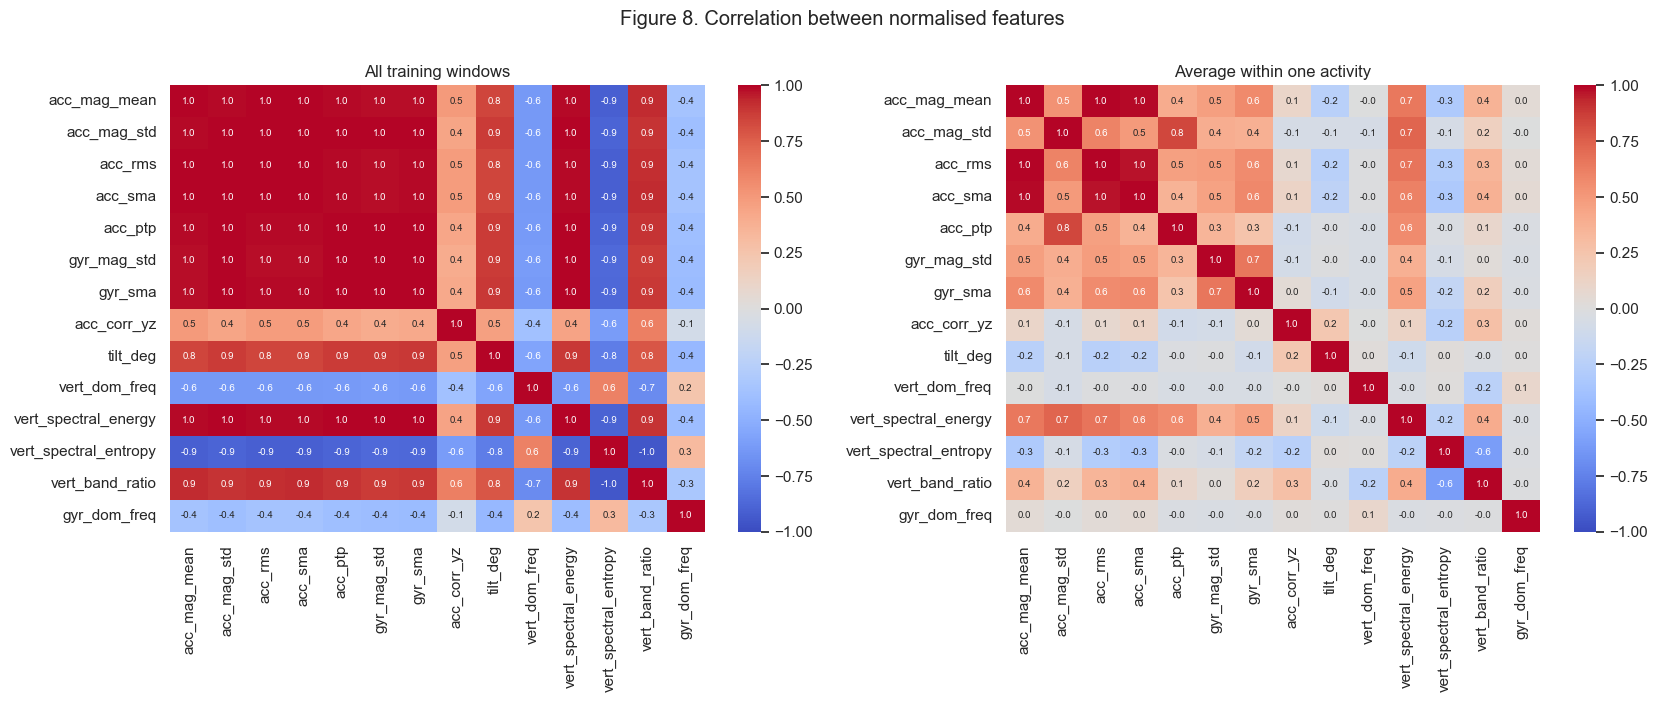

,feature A,feature B,within-activity correlation
0,acc_mag_mean,acc_rms,0.99
1,acc_mag_mean,acc_sma,0.98
2,acc_mag_std,acc_ptp,0.84
3,acc_rms,acc_sma,0.97


In [17]:
within = sum(train_feat[train_feat.activity == a][ft.FEATURE_NAMES].corr() for a in ACTIVITIES) / len(ACTIVITIES)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.heatmap(train_feat[ft.FEATURE_NAMES].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("All training windows")
sns.heatmap(within, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Average within one activity")
fig.suptitle("Figure 8. Correlation between normalised features", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

pairs = [(a, b, within.loc[a, b]) for i, a in enumerate(ft.FEATURE_NAMES)
         for b in ft.FEATURE_NAMES[i + 1:] if abs(within.loc[a, b]) > 0.8]
pd.DataFrame(pairs, columns=["feature A", "feature B", "within-activity correlation"]).round(2)

Mean, RMS and SMA of the acceleration are almost the same signal inside one activity (r ≈ 0.97–0.99), and peak-to-peak is close to the standard deviation. The diagonal model therefore counts the same evidence several times, which makes the emission probabilities over-confident. I discuss this in the report.

## 4. Hidden Markov Model

### Model components

| Element | Definition in my model |
|---|---|
| Hidden states **Z** | 4 activities: standing, walking, jumping, still |
| Observations **X** | one 14-dimensional normalised feature vector per 2 s window (one per second) |
| Transition probabilities **A** | 4 × 4 matrix, `A[i, j] = P(z_t = j | z_{t-1} = i)` |
| Emission probabilities **B** | one multivariate Gaussian per state, `P(x_t | z_t = k) = N(x_t; μ_k, Σ_k)` with diagonal Σ_k |
| Initial probabilities **π** | `π_k = P(z_1 = k)` |

### Which algorithms suit this task

- **Baum–Welch (EM)** learns π, A and the Gaussian emissions by maximising the likelihood of the training sequences. Its E-step uses **forward–backward** to get the state posteriors. I stop when the log-likelihood improves by less than ε = 10⁻⁴.
- **Viterbi** finds the single most likely activity sequence for a whole recording. It scores whole paths, so the transition matrix can remove isolated one-window mistakes. That raises **sensitivity** (fewer missed windows of an activity) and **specificity** (fewer false switches into another activity), and with them overall **accuracy**.
- The **forward** pass also gives the sequence log-likelihood that I use for the convergence check.

I run every algorithm in log space with log-sum-exp to avoid numerical underflow.

### Implementation choices

- **Diagonal covariance**: with 14 features and about 140 windows per state, a full covariance (105 parameters per state) overfits my very consistent training clips.
- **Variance floor of 0.01** (1 % of the normalised variance), so a state is never infinitely sure about a feature that hardly varied in training.
- **Dirichlet pseudo-count of 1** on the transitions, so no transition has a probability of exactly zero.
- **Initialisation**: I seed the state means from the labelled windows so hidden state k keeps the meaning of activity k. π and A start uniform and every covariance starts at the pooled covariance, then Baum–Welch learns them.
- **Chained training sessions**: each of my clips contains one activity, so on its own it has no transitions. I shuffle my 80 clips (fixed seed) and join them into 20 sessions of 4 clips, about 36 s each, which is the length of my real test sessions. Baum–Welch can then learn how long an activity lasts and how often it switches.

### My implementation

I print the core methods of my `GaussianHMM` class (`src/hmm.py`) so the algorithms can be read directly here.

In [18]:
def show_source(*functions):
    for function in functions:
        print(f"# ---- {function.__qualname__} " + "-" * max(0, 60 - len(function.__qualname__)))
        print(textwrap.dedent(inspect.getsource(function)))


show_source(GaussianHMM._log_emission, GaussianHMM._forward, GaussianHMM._backward)

# ---- GaussianHMM._log_emission -----------------------------------
def _log_emission(self, X: np.ndarray) -> np.ndarray:
    n, d = X.shape
    out = np.empty((n, self.n_states))
    for k in range(self.n_states):
        diff = X - self.means_[k]
        if self.covariance_type == "diag":
            var = self.covars_[k]
            out[:, k] = -0.5 * (d * LOG_2PI + np.sum(np.log(var)) + np.sum(diff ** 2 / var, axis=1))
        else:
            chol = np.linalg.cholesky(self.covars_[k])
            solved = np.linalg.solve(chol, diff.T)
            log_det = 2 * np.sum(np.log(np.diag(chol)))
            out[:, k] = -0.5 * (d * LOG_2PI + log_det + np.sum(solved ** 2, axis=0))
    return out

# ---- GaussianHMM._forward ----------------------------------------
def _forward(self, log_b: np.ndarray) -> np.ndarray:
    n = log_b.shape[0]
    log_a = np.log(self.transmat_)
    log_alpha = np.empty((n, self.n_states))
    log_alpha[0] = np.log(self.startprob_) + log_b[0]
    for t in ran

In [19]:
show_source(GaussianHMM._e_step, GaussianHMM._m_step, GaussianHMM.fit)

# ---- GaussianHMM._e_step -----------------------------------------
def _e_step(self, X: np.ndarray) -> tuple:
    log_b = self._log_emission(X)
    log_alpha = self._forward(log_b)
    log_beta = self._backward(log_b)
    log_likelihood = logsumexp(log_alpha[-1])

    gamma = np.exp(log_alpha + log_beta - log_likelihood)

    xi_sum = np.zeros((self.n_states, self.n_states))
    if len(X) > 1:
        log_a = np.log(self.transmat_)
        log_xi = (log_alpha[:-1, :, None] + log_a[None, :, :]
                  + (log_b[1:] + log_beta[1:])[:, None, :] - log_likelihood)
        xi_sum = np.exp(logsumexp(log_xi, axis=0))
    return gamma, xi_sum, log_likelihood

# ---- GaussianHMM._m_step -----------------------------------------
def _m_step(self, sequences: list, gammas: list, xi_total: np.ndarray) -> None:
    start = sum(g[0] for g in gammas)
    self.startprob_ = (start + 1) / (start + 1).sum()
    self.transmat_ = self._normalise_transitions(xi_total)

    X = np.vstack(sequences)


In [20]:
show_source(GaussianHMM.viterbi, chain_clips, initialise)

# ---- GaussianHMM.viterbi -----------------------------------------
def viterbi(self, X: np.ndarray) -> tuple:
    log_b = self._log_emission(X)
    log_a = np.log(self.transmat_)
    n = len(X)

    delta = np.empty((n, self.n_states))
    backpointer = np.zeros((n, self.n_states), dtype=int)
    delta[0] = np.log(self.startprob_) + log_b[0]
    for t in range(1, n):
        candidates = delta[t - 1][:, None] + log_a
        backpointer[t] = np.argmax(candidates, axis=0)
        delta[t] = candidates[backpointer[t], np.arange(self.n_states)] + log_b[t]

    path = np.empty(n, dtype=int)
    path[-1] = np.argmax(delta[-1])
    for t in range(n - 2, -1, -1):
        path[t] = backpointer[t + 1, path[t + 1]]
    return np.array(self.states)[path], float(delta[-1, path[-1]])

# ---- chain_clips -------------------------------------------------
def chain_clips(sequences: list, labels: list, clips_per_session: int = CLIPS_PER_SESSION,
                seed: int = CHAIN_SEED) -> tuple:
    o

### Training with Baum–Welch

In [21]:
clip_X, clip_y, clip_files = to_sequences(train_feat)
train_X, train_y = chain_clips(clip_X, clip_y)
test_X, test_y, test_files = to_sequences(test_feat)
print(f"{len(clip_X)} clips joined into {len(train_X)} training sessions of {CLIPS_PER_SESSION} clips, "
      f"{sum(len(x) for x in train_X)} observations, {train_X[0].shape[1]} features")
print(f"Session lengths: {min(len(x) for x in train_X)}–{max(len(x) for x in train_X)} windows (≈ seconds)")
HMM_CONFIG

80 clips joined into 20 training sessions of 4 clips, 577 observations, 14 features
Session lengths: 27–31 windows (≈ seconds)


{'covariance_type': 'diag',
 'tol': 0.0001,
 'max_iter': 200,
 'min_covar': 0.01,
 'transition_prior': 1.0}

In [22]:
hmm = train_hmm(train_feat, verbose=True, save=True)
print(f"\nConverged: {hmm.converged_} after {hmm.n_iter_} iterations (stopping rule: |Δ log-likelihood| < {hmm.tol})")

iter   1  log-likelihood    -8782.641  delta        inf
iter   2  log-likelihood     1173.397  delta 9956.03829
iter   3  log-likelihood     3283.552  delta 2110.15554
iter   4  log-likelihood     3283.561  delta    0.00829
iter   5  log-likelihood     3283.561  delta    0.00000

Converged: True after 5 iterations (stopping rule: |Δ log-likelihood| < 0.0001)


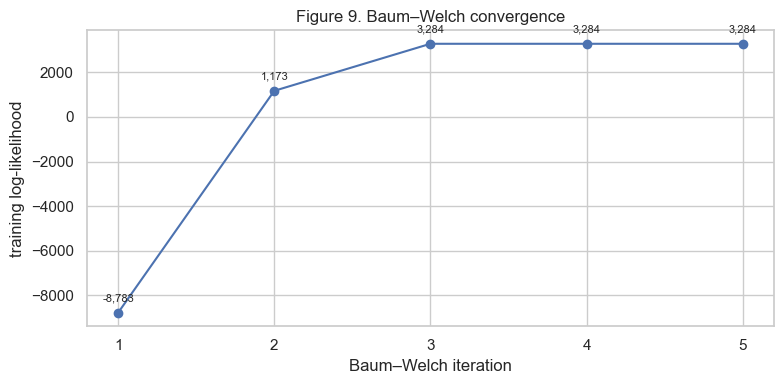

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
iterations = np.arange(1, len(hmm.history_) + 1)
ax.plot(iterations, hmm.history_, marker="o")
ax.set_xticks(iterations)
ax.set_xlabel("Baum–Welch iteration")
ax.set_ylabel("training log-likelihood")
ax.set_title("Figure 9. Baum–Welch convergence")
for x, y in zip(iterations, hmm.history_):
    ax.annotate(f"{y:,.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS / "convergence.png", dpi=150, bbox_inches="tight")
plt.show()

### What did Baum–Welch change?

I compare three models: the fully supervised estimate (counted directly from the labels), my starting point before training, and the model after Baum–Welch.

In [24]:
y_test = np.concatenate(test_y)
supervised = GaussianHMM(ACTIVITIES, **HMM_CONFIG).fit_supervised(train_X, train_y)
start = initialise(GaussianHMM(ACTIVITIES, **HMM_CONFIG), train_X, train_y)

rows = []
for name, model in [("supervised (counted from labels)", supervised),
                    ("start: label means, uniform A and π, pooled covariance", start),
                    ("after Baum–Welch", hmm)]:
    pred = np.concatenate([model.predict(x) for x in test_X])
    rows.append({"model": name, "train log-likelihood": model.score(train_X),
                 "test log-likelihood": model.score(test_X), "test accuracy": np.mean(pred == y_test),
                 "mean self-transition": np.mean(np.diag(model.transmat_))})
pd.DataFrame(rows).round(3)

,model,train log-likelihood,test log-likelihood,test accuracy,mean self-transition
0,supervised (counted from labels),3283.561,-1654.942,0.936,0.892
1,"start: label means, uniform A and π, pooled covariance",-8782.641,-1249.772,0.782,0.250
2,after Baum–Welch,3283.561,-1654.942,0.936,0.892


Baum–Welch raises the training log-likelihood from −8,783 to 3,284 and test accuracy from 78.2 % to 93.6 %. It learns the transition matrix (mean self-transition from 0.25 to 0.89) and the covariances from the data. It ends at the same point as the supervised estimate, which is expected: my training windows are clean and well separated, so the state posteriors become almost identical to the labels.

### Baum–Welch from random starts

To check that Baum–Welch works without any label information, I start it 10 times from random means (4 random training windows), a uniform A and π and the pooled covariance. Hidden states then have no names, so I match each state to an activity with the **Hungarian algorithm** on the training confusion matrix.

In [25]:
X_all, y_all = np.vstack(train_X), np.concatenate(train_y)
pooled = np.cov(X_all, rowvar=False, bias=True)
rows = []
for seed in range(10):
    rng = np.random.default_rng(seed)
    model = GaussianHMM(ACTIVITIES, **HMM_CONFIG)
    model.means_ = X_all[rng.choice(len(X_all), len(ACTIVITIES), replace=False)]
    model.covars_ = np.array([model._regularise(pooled) for _ in ACTIVITIES])
    model.startprob_ = np.full(len(ACTIVITIES), 1 / len(ACTIVITIES))
    model.transmat_ = np.full((len(ACTIVITIES), len(ACTIVITIES)), 1 / len(ACTIVITIES))
    model.fit(train_X)

    decoded = np.concatenate([model.predict(x) for x in train_X])
    overlap = np.array([[np.sum((y_all == a) & (decoded == s)) for s in ACTIVITIES] for a in ACTIVITIES])
    act_idx, state_idx = linear_sum_assignment(-overlap)
    mapping = {ACTIVITIES[s]: ACTIVITIES[a] for a, s in zip(act_idx, state_idx)}
    test_pred = np.array([mapping[s] for s in np.concatenate([model.predict(x) for x in test_X])])
    rows.append({"seed": seed, "iterations": model.n_iter_, "converged": model.converged_,
                 "final log-likelihood": model.history_[-1],
                 "train accuracy after matching": overlap[act_idx, state_idx].sum() / len(y_all),
                 "test accuracy": np.mean(test_pred == y_test)})
restarts = pd.DataFrame(rows)
restarts.round(3)

,seed,iterations,converged,final log-likelihood,train accuracy after matching,test accuracy
0,0,5,True,3283.561,1.000,0.936
1,1,7,True,3283.561,1.000,0.936
2,2,42,True,528.107,0.664,0.564
3,3,14,True,-971.807,0.660,0.641
4,4,25,True,561.625,0.704,0.628
5,5,6,True,3283.561,1.000,0.936
6,6,18,True,561.625,0.704,0.628
7,7,7,True,3283.561,1.000,0.936
8,8,5,True,3283.561,1.000,0.936
9,9,17,True,561.625,0.704,0.628


In [26]:
best = restarts["final log-likelihood"].max()
print(f"{np.sum(np.isclose(restarts['final log-likelihood'], best))} of {len(restarts)} random starts reach the "
      f"best log-likelihood ({best:,.1f}), the same value as my main model ({hmm.history_[-1]:,.1f}).")

5 of 10 random starts reach the best log-likelihood (3,283.6), the same value as my main model (3,283.6).


Every run converges. Five of ten random starts find the same optimum as my main model (log-likelihood 3,283.6) and reach the same 93.6 % test accuracy. The other five stop at lower local optima (log-likelihood −972 to 562, with only 66–70 % of training windows matched to the right activity). EM only guarantees a local maximum, which is why I seed the means from the labels.

### Learned parameters

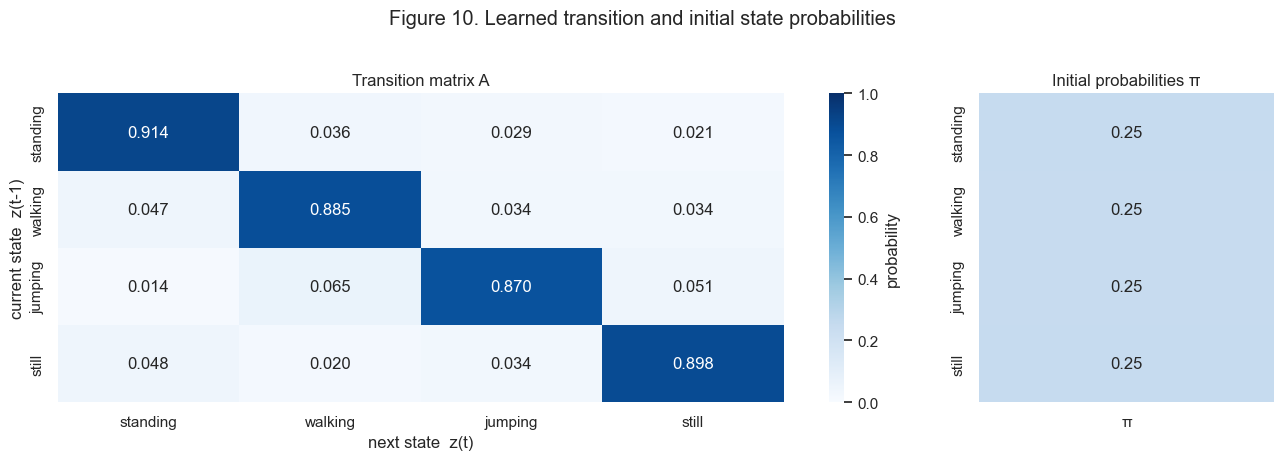

,self-transition,expected stay (windows ≈ seconds)
standing,0.914,11.667
walking,0.885,8.706
jumping,0.870,7.667
still,0.898,9.800


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [4, 1.3]})
sns.heatmap(pd.DataFrame(hmm.transmat_, index=ACTIVITIES, columns=ACTIVITIES), annot=True, fmt=".3f",
            cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "probability"})
axes[0].set_xlabel("next state  z(t)")
axes[0].set_ylabel("current state  z(t-1)")
axes[0].set_title("Transition matrix A")
sns.heatmap(pd.DataFrame(hmm.startprob_, index=ACTIVITIES, columns=["π"]), annot=True, fmt=".2f",
            cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Initial probabilities π")
fig.suptitle("Figure 10. Learned transition and initial state probabilities", y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / "transition_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"self-transition": np.diag(hmm.transmat_),
              "expected stay (windows ≈ seconds)": 1 / (1 - np.diag(hmm.transmat_))}, index=ACTIVITIES).round(3)

### Why I chain the clips

I also train the same model on the 80 clips as separate sequences, like my first version, and compare the transition matrices.

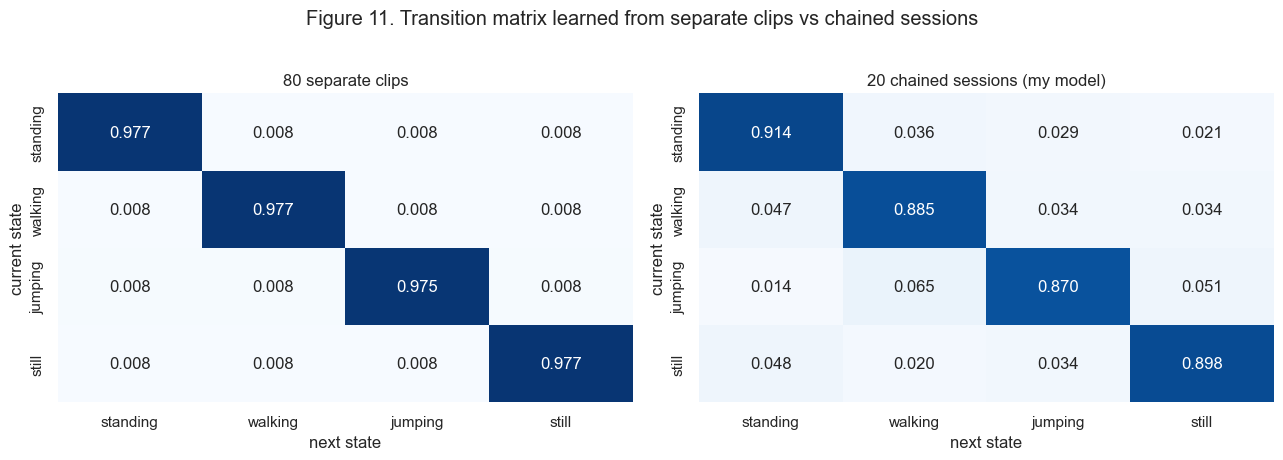

,training data,mean self-transition,expected stay (s),test accuracy
0,separate clips,0.977,42.75,0.936
1,chained sessions,0.892,9.46,0.936


In [28]:
separate = initialise(GaussianHMM(ACTIVITIES, **HMM_CONFIG), clip_X, clip_y).fit(clip_X)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (title, model) in zip(axes, [("80 separate clips", separate), ("20 chained sessions (my model)", hmm)]):
    sns.heatmap(pd.DataFrame(model.transmat_, index=ACTIVITIES, columns=ACTIVITIES), annot=True, fmt=".3f",
                cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel("next state")
    ax.set_ylabel("current state")
fig.suptitle("Figure 11. Transition matrix learned from separate clips vs chained sessions", y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / "transition_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for name, model in [("separate clips", separate), ("chained sessions", hmm)]:
    pred = np.concatenate([model.predict(x) for x in test_X])
    rows.append({"training data": name, "mean self-transition": np.mean(np.diag(model.transmat_)),
                 "expected stay (s)": np.mean(1 / (1 - np.diag(model.transmat_))),
                 "test accuracy": np.mean(pred == y_test)})
pd.DataFrame(rows).round(3)

With separate clips every self-transition is about 0.977. That value comes almost entirely from the pseudo-count, because a single-activity clip contains no switches, and it means the model expects an activity to last about 43 s. With chained sessions the self-transitions are 0.87–0.91, an expected stay of about 9.5 s, which is close to my test sessions (about 10 s per activity). Test accuracy stays at 93.6 %, because my emissions are confident enough to decide almost every window on their own. The off-diagonal values (0.01–0.07) reflect the random order in which I joined my clips, not how I really switch between activities.

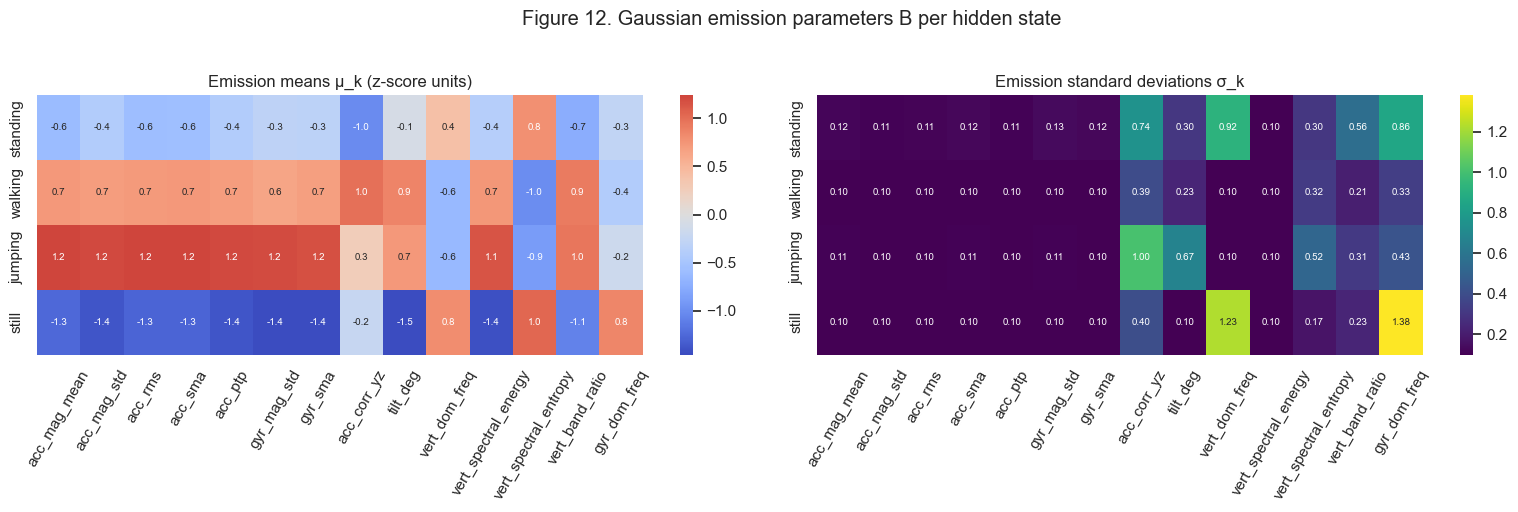

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(pd.DataFrame(hmm.means_, index=ACTIVITIES, columns=ft.FEATURE_NAMES), cmap="coolwarm",
            center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Emission means μ_k (z-score units)")
sns.heatmap(pd.DataFrame(np.sqrt(hmm.covars_), index=ACTIVITIES, columns=ft.FEATURE_NAMES), cmap="viridis",
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Emission standard deviations σ_k")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Figure 12. Gaussian emission parameters B per hidden state", y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / "emission_parameters.png", dpi=150, bbox_inches="tight")
plt.show()

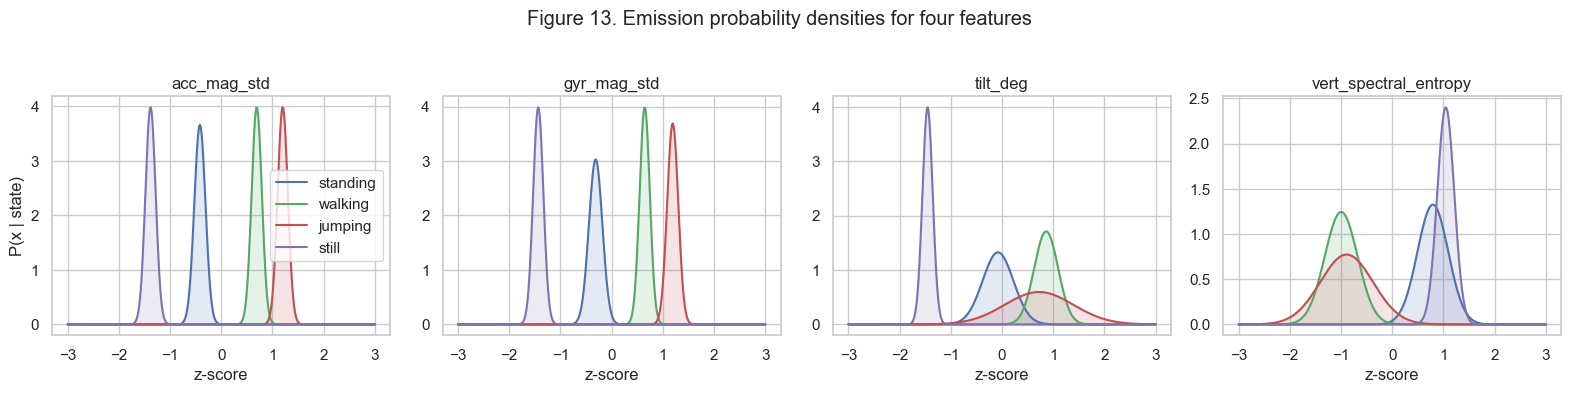

In [30]:
show = ["acc_mag_std", "gyr_mag_std", "tilt_deg", "vert_spectral_entropy"]
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.8))
grid = np.linspace(-3, 3, 400)
for ax, feat in zip(axes, show):
    j = ft.FEATURE_NAMES.index(feat)
    for k, activity in enumerate(ACTIVITIES):
        density = norm.pdf(grid, hmm.means_[k, j], np.sqrt(hmm.covars_[k, j]))
        ax.plot(grid, density, color=COLORS[activity], label=activity)
        ax.fill_between(grid, density, color=COLORS[activity], alpha=0.15)
    ax.set_title(feat)
    ax.set_xlabel("z-score")
axes[0].set_ylabel("P(x | state)")
axes[0].legend()
fig.suptitle("Figure 13. Emission probability densities for four features", y=1.03)
fig.tight_layout()
fig.savefig(PLOTS / "emission_densities.png", dpi=150, bbox_inches="tight")
plt.show()

### Correctness check

I compare my forward log-likelihood, Viterbi path and forward–backward posteriors with brute-force enumeration of every possible state path (3⁶ = 729 paths) on a small random model.

In [31]:
rng = np.random.default_rng(1)
toy = GaussianHMM(["a", "b", "c"], covariance_type="diag")
toy.startprob_ = rng.dirichlet(np.ones(3))
toy.transmat_ = rng.dirichlet(np.ones(3), size=3)
toy.means_ = rng.normal(size=(3, 2))
toy.covars_ = np.array([[0.5, 0.5], [1.0, 1.0], [2.0, 2.0]])
X_toy = rng.normal(size=(6, 2))

log_b = toy._log_emission(X_toy)
paths = list(itertools.product(range(3), repeat=len(X_toy)))
path_scores = np.array([
    np.log(toy.startprob_[p[0]]) + log_b[0, p[0]]
    + sum(np.log(toy.transmat_[p[t - 1], p[t]]) + log_b[t, p[t]] for t in range(1, len(p)))
    for p in paths])

best_path = [toy.states[i] for i in paths[np.argmax(path_scores)]]
posterior = np.zeros((len(X_toy), 3))
for p, w in zip(paths, np.exp(path_scores - logsumexp(path_scores))):
    posterior[np.arange(len(p)), list(p)] += w

pd.Series({
    "forward log-likelihood == brute force": np.isclose(toy.score([X_toy]), logsumexp(path_scores)),
    "Viterbi path == best enumerated path": list(toy.predict(X_toy)) == best_path,
    "forward-backward posteriors == brute force": np.allclose(toy.predict_proba(X_toy), posterior),
})

forward log-likelihood == brute force         True
Viterbi path == best enumerated path          True
forward-backward posteriors == brute force    True
dtype: bool

## 5. Evaluation on unseen data

My two test files are **new sessions recorded on 28 October at 08:54 and 08:56, after all training clips**. Each is one continuous recording with all four activities in a different order, so the model must detect real transitions between activities (in training it only saw the transitions between my chained clips):

- `mixed_01.csv`: standing → walking → jumping → still
- `mixed_02.csv`: walking → still → jumping → standing

I never used them for training, for the normalisation statistics or for Baum–Welch.

**Note:** in the table, *Number of Samples* is the number of **2 s windows** (one HMM observation each), not raw sensor readings.

In [32]:
predictions, metrics = ev.evaluate(hmm, test_feat, save=True)
y_true, y_pred = predictions["activity"].to_numpy(), predictions["viterbi"].to_numpy()

table = metrics[["State (Activity)", "Number of Samples", "Sensitivity", "Specificity", "Overall Accuracy"]].copy()
table["State (Activity)"] = table["State (Activity)"].str.capitalize()
table.round(3)

,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,Standing,18,0.889,0.967,0.936
1,Walking,23,0.957,0.982,0.936
2,Jumping,21,1.000,0.965,0.936
3,Still,16,0.875,1.000,0.936


In [33]:
metrics.round(3)

,State (Activity),Number of Samples,Sensitivity,Specificity,Precision,Accuracy (one-vs-rest),Overall Accuracy
0,standing,18,0.889,0.967,0.889,0.949,0.936
1,walking,23,0.957,0.982,0.957,0.974,0.936
2,jumping,21,1.000,0.965,0.913,0.974,0.936
3,still,16,0.875,1.000,1.000,0.974,0.936


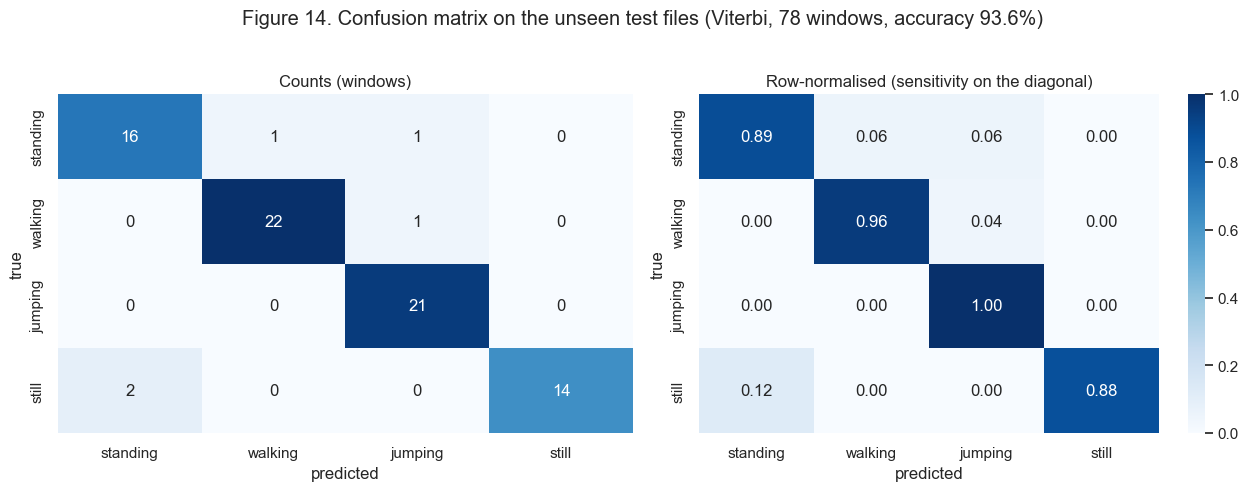

In [34]:
cm = ev.confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Counts (windows)")
sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Row-normalised (sensitivity on the diagonal)")
fig.suptitle(f"Figure 14. Confusion matrix on the unseen test files (Viterbi, {len(y_true)} windows, "
             f"accuracy {np.mean(y_true == y_pred):.1%})", y=1.02)
fig.tight_layout()
fig.savefig(PLOTS / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

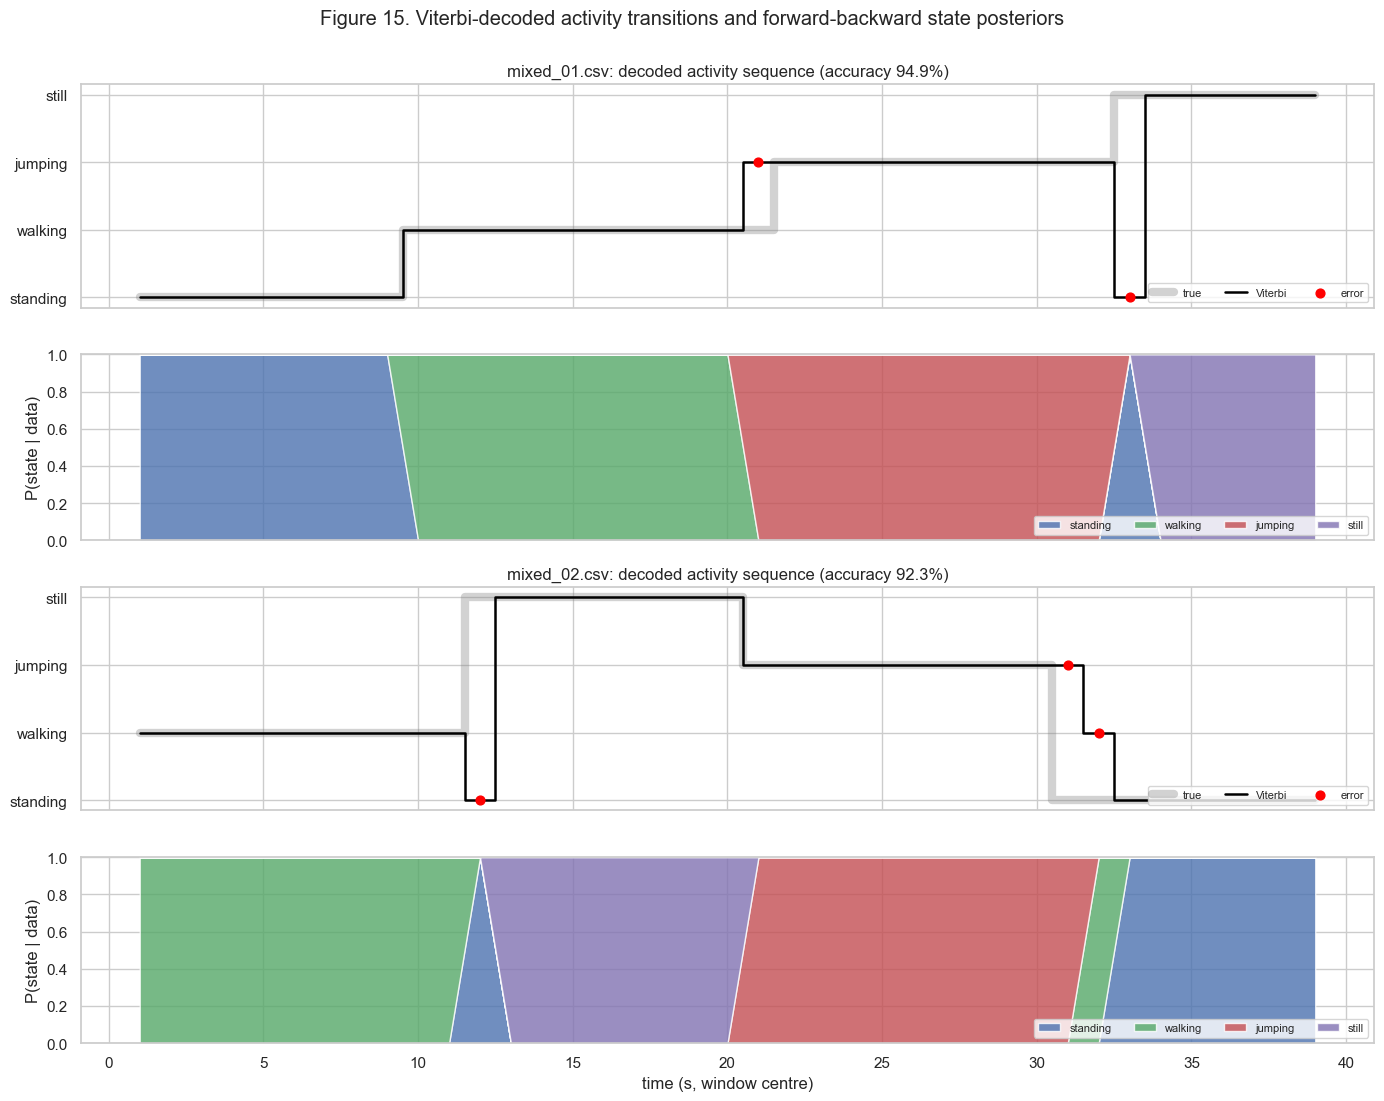

In [35]:
state_index = {s: i for i, s in enumerate(ACTIVITIES)}
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 1, 1.2, 1]})
for (file, df), (ax_path, ax_prob) in zip(predictions.groupby("file"), [axes[:2], axes[2:]]):
    t = df["start_s"] + pp.WINDOW_S / 2
    ax_path.step(t, df["activity"].map(state_index), where="mid", lw=6, alpha=0.35, color="grey", label="true")
    ax_path.step(t, df["viterbi"].map(state_index), where="mid", lw=1.8, color="black", label="Viterbi")
    wrong = df["activity"] != df["viterbi"]
    ax_path.scatter(t[wrong], df.loc[wrong, "viterbi"].map(state_index), color="red", zorder=5, s=40, label="error")
    ax_path.set_yticks(range(len(ACTIVITIES)))
    ax_path.set_yticklabels(ACTIVITIES)
    ax_path.set_title(f"{file}: decoded activity sequence (accuracy {np.mean(~wrong):.1%})")
    ax_path.legend(loc="lower right", ncol=3, fontsize=8)
    ax_prob.stackplot(t, *[df[f"p_{s}"] for s in ACTIVITIES], labels=ACTIVITIES,
                      colors=[COLORS[s] for s in ACTIVITIES], alpha=0.8)
    ax_prob.set_ylabel("P(state | data)")
    ax_prob.set_ylim(0, 1)
    ax_prob.legend(loc="lower right", ncol=4, fontsize=8)
axes[-1].set_xlabel("time (s, window centre)")
fig.suptitle("Figure 15. Viterbi-decoded activity transitions and forward-backward state posteriors", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "decoded_sequences.png", dpi=150, bbox_inches="tight")
plt.show()

### Comparing decoders

I compare three ways to turn my model into predictions:
- **Viterbi**: the best whole sequence.
- **Posterior decoding**: the most likely state per window from forward–backward.
- **Independent windows**: the emission likelihood only, without transitions.

In [36]:
predictions["posterior"] = np.array(ACTIVITIES)[predictions[[f"p_{s}" for s in ACTIVITIES]].to_numpy().argmax(axis=1)]
rows = []
for file, d in predictions.groupby("file"):
    X = test_feat[test_feat.file == file].sort_values("window")[ft.FEATURE_NAMES].to_numpy()
    rows.append({"file": file, "windows": len(d),
                 "Viterbi": np.mean(d["activity"] == d["viterbi"]),
                 "posterior decoding": np.mean(d["activity"] == d["posterior"]),
                 "independent windows": np.mean(d["activity"] == d["independent"]),
                 "log-likelihood per window": hmm.score([X]) / len(d)})
rows.append({"file": "both", "windows": len(predictions),
             "Viterbi": np.mean(predictions["activity"] == predictions["viterbi"]),
             "posterior decoding": np.mean(predictions["activity"] == predictions["posterior"]),
             "independent windows": np.mean(predictions["activity"] == predictions["independent"])})
pd.DataFrame(rows).set_index("file").round(3)

,windows,Viterbi,posterior decoding,independent windows,log-likelihood per window
file,,,,,
mixed_01.csv,39,0.949,0.949,0.949,-18.815
mixed_02.csv,39,0.923,0.923,0.923,-23.619
both,78,0.936,0.936,0.936,NaN


### Where do the errors come from?

A 2 s window that starts just before an activity change contains two activities and gets the majority label, so it is ambiguous by construction. I compute the purity of every test window from the sample-level labels.

In [37]:
purity = []
for seq in test_seqs:
    labels = seq["signal"]["activity"].to_numpy()
    for i, start in enumerate(range(0, len(labels) - pp.WINDOW_SIZE + 1, pp.STEP_SIZE)):
        segment = labels[start:start + pp.WINDOW_SIZE]
        purity.append({"file": seq["file"], "window": i, "purity": np.mean(segment == seq["labels"][i])})
predictions = predictions.merge(pd.DataFrame(purity), on=["file", "window"])
predictions["boundary window"] = predictions["purity"] < 1.0
predictions["correct"] = predictions["activity"] == predictions["viterbi"]

display(predictions[~predictions["correct"]][["file", "window", "start_s", "activity", "viterbi", "purity"]].round(2))

(predictions.groupby("boundary window")["correct"].agg(windows="size", accuracy="mean")
 .rename(index={False: "fully inside one activity", True: "spans an activity change"}).round(3))

,file,window,start_s,activity,viterbi,purity
20,mixed_01.csv,20,20.0,walking,jumping,0.60
32,mixed_01.csv,32,32.0,still,standing,0.84
50,mixed_02.csv,11,11.0,still,standing,0.66
69,mixed_02.csv,30,30.0,standing,jumping,0.53
70,mixed_02.csv,31,31.0,standing,walking,1.00


,windows,accuracy
boundary window,,
fully inside one activity,66,0.985
spans an activity change,12,0.667


### How different is the test data?

I measure how far the mean of each normalised feature moved between my training clips and my test sessions (in training standard deviations).

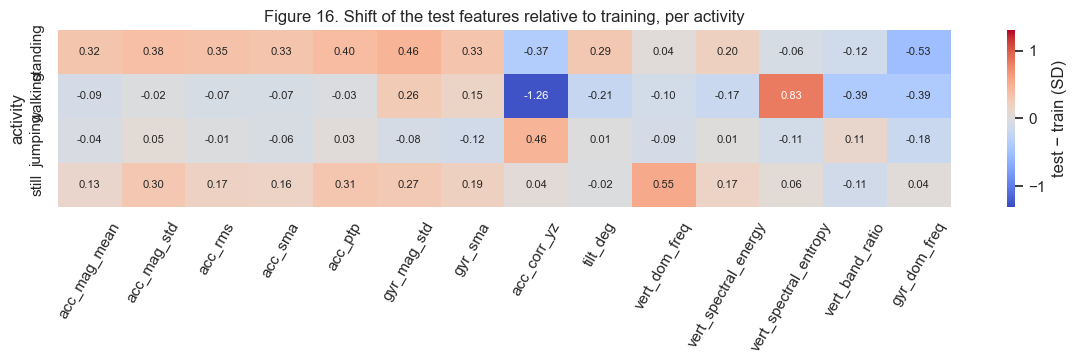

Intensity features are 0.21–0.36 SD higher in the test sessions.


,mean |shift| (SD)
activity,
standing,0.30
walking,0.29
jumping,0.10
still,0.18


In [38]:
shift = (test_feat.groupby("activity")[ft.FEATURE_NAMES].mean()
         - train_feat.groupby("activity")[ft.FEATURE_NAMES].mean()).reindex(ACTIVITIES)

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(shift, cmap="coolwarm", center=0, vmin=-1.3, vmax=1.3, annot=True, fmt=".2f",
            annot_kws={"size": 8}, ax=ax, cbar_kws={"label": "test − train (SD)"})
ax.tick_params(axis="x", rotation=60)
ax.set_title("Figure 16. Shift of the test features relative to training, per activity")
fig.tight_layout()
fig.savefig(PLOTS / "test_shift.png", dpi=150, bbox_inches="tight")
plt.show()

intensity = ["acc_mag_mean", "acc_mag_std", "acc_rms", "acc_sma", "acc_ptp", "gyr_mag_std", "gyr_sma"]
overall = test_feat[ft.FEATURE_NAMES].mean() - train_feat[ft.FEATURE_NAMES].mean()
print(f"Intensity features are {overall[intensity].min():.2f}–{overall[intensity].max():.2f} SD higher in the test sessions.")
shift.abs().mean(axis=1).round(2).rename("mean |shift| (SD)").to_frame()

**Limitation of my test data.** I recorded both test sessions on the morning of 28 October, in the same place, with the same phone and position as my training clips. They are new recordings, but they do not test a new environment, a new phone position (for example a pocket) or a different person, so the 93.6 % accuracy is likely optimistic for real use.

### Robustness to feature noise

On clean data Viterbi and independent windows give the same result. To see how much the transition matrix contributes, I add increasing Gaussian noise to the normalised test features (a simple model of a noisier sensor or a different phone placement) and average over 20 random draws.

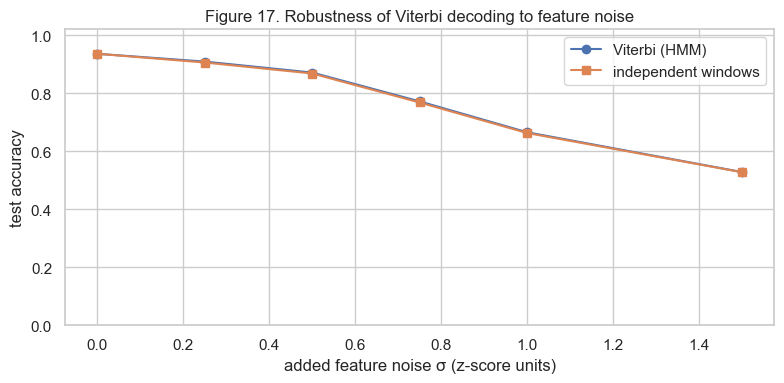

,noise σ (z units),Viterbi,independent
0,0.00,0.936,0.936
1,0.25,0.909,0.906
2,0.50,0.871,0.868
3,0.75,0.772,0.768
4,1.00,0.665,0.663
5,1.50,0.528,0.528


In [39]:
rng = np.random.default_rng(42)
rows = []
for noise in [0.0, 0.25, 0.5, 0.75, 1.0, 1.5]:
    vit, ind = [], []
    for _ in range(20):
        noisy = [x + rng.normal(0, noise, x.shape) for x in test_X]
        vit.append(np.mean(np.concatenate([hmm.predict(x) for x in noisy]) == y_test))
        ind.append(np.mean(np.concatenate([ev.predict_independent(hmm, x) for x in noisy]) == y_test))
    rows.append({"noise σ (z units)": noise, "Viterbi": np.mean(vit), "independent": np.mean(ind)})
robustness = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(robustness["noise σ (z units)"], robustness["Viterbi"], marker="o", label="Viterbi (HMM)")
ax.plot(robustness["noise σ (z units)"], robustness["independent"], marker="s", label="independent windows")
ax.set_xlabel("added feature noise σ (z-score units)")
ax.set_ylabel("test accuracy")
ax.set_ylim(0, 1.02)
ax.set_title("Figure 17. Robustness of Viterbi decoding to feature noise")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "noise_robustness.png", dpi=150, bbox_inches="tight")
plt.show()
robustness.round(3)

### Handling a different sampling rate

I only had one phone, so to show that my pipeline handles a different device I simulate a **50 Hz phone** by keeping every second sample of my test sessions. The 50 Hz signal goes through the same pipeline: it is interpolated onto the 100 Hz grid, low-pass filtered at 20 Hz (below the 25 Hz Nyquist limit of 50 Hz), windowed and normalised with the training statistics. I then decode it with the model trained at 100 Hz.

In [40]:
def features_from_dataframe(df):
    signal = pp.lowpass_filter(pp.resample_uniform(df))
    windows, labels, starts = pp.make_windows(signal)
    seq = {"file": "sim", "windows": windows, "labels": labels, "start_s": starts}
    return normalizer.transform(ft.log_transform(ft.extract_features([seq])))

rows = []
for path in sorted((ROOT / "data" / "test").glob("mixed_*.csv")):
    full = pp.load_recording(path)
    for rate, step in [(100, 1), (50, 2)]:
        down = full.iloc[::step].reset_index(drop=True)
        down["seconds_elapsed"] = (down["time"] - down["time"].iloc[0]) / 1e9
        feats = features_from_dataframe(down)
        pred = hmm.predict(feats[ft.FEATURE_NAMES].to_numpy())
        rows.append({"file": path.name, "recorded at": f"{rate} Hz",
                     "median interval (ms)": np.median(np.diff(down["time"])) / 1e6,
                     "windows": len(feats), "accuracy": np.mean(pred == feats["activity"].to_numpy())})
pd.DataFrame(rows).round(3)

,file,recorded at,median interval (ms),windows,accuracy
0,mixed_01.csv,100 Hz,10.072,39,0.949
1,mixed_01.csv,50 Hz,20.143,39,0.923
2,mixed_02.csv,100 Hz,10.072,39,0.923
3,mixed_02.csv,50 Hz,20.144,39,0.923


### Sensitivity to the emission variance floor

**Note: I chose the variance floor of 0.01 after viewing these test results.** Leave-5-clips-out cross-validation on the training clips scores 100 % for every value, so it could not choose the floor. I show all values here for transparency.

In [41]:
rows = []
for floor in [1e-3, 1e-2, 5e-2, 1e-1, 2e-1]:
    candidate = initialise(GaussianHMM(ACTIVITIES, **{**HMM_CONFIG, "min_covar": floor}), train_X, train_y)
    candidate.fit(train_X)
    pred = np.concatenate([candidate.predict(x) for x in test_X])
    rows.append({"variance floor": floor, "Baum–Welch iterations": candidate.n_iter_,
                 "test accuracy": np.mean(pred == y_test)})
pd.DataFrame(rows).round(3)

,variance floor,Baum–Welch iterations,test accuracy
0,0.001,5,0.859
1,0.010,5,0.936
2,0.050,5,0.923
3,0.100,6,0.846
4,0.200,7,0.872


## 6. Conclusion

- My HMM reaches **93.6 % accuracy** on two unseen sessions, and **98.5 %** on windows that lie inside a single activity. Most errors are windows that span an activity change.
- **Jumping** is the easiest activity (sensitivity 1.00). **Standing vs still**, and the moments just after jumping, are the hardest.
- After chaining my clips into sessions, the learned self-transitions are 0.87–0.91, so the model expects an activity to last about 9.5 s, close to the ~10 s per activity in my test sessions. Activities persist instead of switching every second, which is realistic. The off-diagonal values come from the random order of my chained clips, so they do not show which switches are more likely in real life.
- Baum–Welch converges in 5 iterations with a log-likelihood stopping rule. Five of ten random starts find the same optimum.
- My test sessions come from the same morning, place, phone and phone position as part of my training data, so the result is likely optimistic for real use.
- Next steps: recording real continuous sessions in other places and phone positions, removing duplicate features or using a full covariance, and adding more participants and phones.

### References

[1] L. R. Rabiner, "A tutorial on hidden Markov models and selected applications in speech recognition," *Proc. IEEE*, vol. 77, no. 2, pp. 257–286, Feb. 1989, doi: [10.1109/5.18626](https://doi.org/10.1109/5.18626).  
[2] A. J. Viterbi, "Error bounds for convolutional codes and an asymptotically optimum decoding algorithm," *IEEE Trans. Inf. Theory*, vol. 13, no. 2, pp. 260–269, Apr. 1967, doi: [10.1109/TIT.1967.1054010](https://doi.org/10.1109/TIT.1967.1054010).  
[3] L. E. Baum, T. Petrie, G. Soules, and N. Weiss, "A maximization technique occurring in the statistical analysis of probabilistic functions of Markov chains," *Ann. Math. Statist.*, vol. 41, no. 1, pp. 164–171, Feb. 1970, doi: [10.1214/aoms/1177697196](https://doi.org/10.1214/aoms/1177697196).  
[4] C. M. Bishop, *Pattern Recognition and Machine Learning*. New York, NY, USA: Springer, 2006. [Online]. Available: [microsoft.com/en-us/research/publication/pattern-recognition-machine-learning](https://www.microsoft.com/en-us/research/publication/pattern-recognition-machine-learning/)  
[5] A. Bulling, U. Blanke, and B. Schiele, "A tutorial on human activity recognition using body-worn inertial sensors," *ACM Comput. Surv.*, vol. 46, no. 3, Art. no. 33, Jan. 2014, doi: [10.1145/2499621](https://doi.org/10.1145/2499621).  
[6] D. Anguita, A. Ghio, L. Oneto, X. Parra, and J. L. Reyes-Ortiz, "A public domain dataset for human activity recognition using smartphones," in *Proc. ESANN*, Bruges, Belgium, 2013, pp. 437–442. [Online]. Available: [esann.org/.../es2013-84.pdf](https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf)